# In-context Learning and Induction Heads (Induction Heads)

**Paper:** [arXiv:2209.11895](https://arxiv.org/abs/2209.11895)
**Authors:** Catherine Olsson, Nelson Elhage, Neel Nanda, Nicholas Joseph, Nova DasSarma, Tom Henighan, Ben Mann, Amanda Askell, Yuntao Bai, Anna Chen, Tom Conerly, Dawn Drain, Deep Ganguli, Zac Hatfield-Dodds, Danny Hernandez, Scott Johnston, Andy Jones, Jackson Kernion, Liane Lovitt, Kamal Ndousse, Dario Amodei, Tom Brown, Jack Clark, Jared Kaplan, Sam McCandlish, Chris Olah (2022; Transformer Circuits Thread / Anthropic)

This notebook trains a small 2-layer attention-only transformer from scratch, detects **induction heads** (attention heads that implement [A][B]...[A]->[B] pattern completion), and shows that ablating them destroys in-context learning.

**Simplifications vs the paper** (same list, same numbers as README and CODE_ARCHITECTURE):
- Synthetic repeated-sequence dataset instead of natural language
- 2 attention-only layers, ~68K parameters instead of billions
- 100 epochs with Adam (lr 1e-3) instead of Anthropic's training schedule
- Prefix-matching score + ablation only; no eigenvalue analysis or PCA of per-token losses


## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
VOCAB_SIZE = 16
SEQ_LEN = 128
N_LAYERS = 2
N_HEADS = 4
D_MODEL = 64
D_HEAD = 16
EPOCHS = 100
BATCH_SIZE = 128
LR = 1e-3
N_TRAIN_SEQS = 4096
N_TEST_SEQS = 512

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Device: cuda


## 2. Data

We create **repeated random sequences**: each sequence has a random first half, and the second
half is an exact copy of the first. This mimics the key property of natural language that makes
induction heads useful: within a single passage, patterns that appeared earlier tend to recur.

When the model sees token A at position i in the second half, it can look back to position i-64
in the first half, find that A was followed by B, and predict B. This is exactly the [A][B]...[A]->[B]
induction pattern. Training on this data gives the model a strong incentive to develop induction heads.


In [2]:
def gen_repeated_sequences(n, half_len, vocab_size, seed=None):
    if seed is not None:
        gen = torch.Generator().manual_seed(seed)
        first_half = torch.randint(0, vocab_size, (n, half_len), generator=gen)
    else:
        first_half = torch.randint(0, vocab_size, (n, half_len))
    return torch.cat([first_half, first_half], dim=1)

half_len = SEQ_LEN // 2

train_data = gen_repeated_sequences(N_TRAIN_SEQS, half_len, VOCAB_SIZE, seed=42)
test_data = gen_repeated_sequences(N_TEST_SEQS, half_len, VOCAB_SIZE, seed=123)
induction_data = gen_repeated_sequences(N_TEST_SEQS, half_len, VOCAB_SIZE, seed=999)

print(f'Vocab size: {VOCAB_SIZE}, Sequence length: {SEQ_LEN} (half: {half_len})')
print(f'Training data: {train_data.shape}')
print(f'Test data: {test_data.shape}')
print(f'Induction detection data: {induction_data.shape}')
print(f'\nExample: first 16 tokens of first half:  {train_data[0, :16].tolist()}')
print(f'Example: first 16 tokens of second half: {train_data[0, half_len:half_len+16].tolist()}')


Vocab size: 16, Sequence length: 128 (half: 64)
Training data: torch.Size([4096, 128])
Test data: torch.Size([512, 128])
Induction detection data: torch.Size([512, 128])

Example: first 16 tokens of first half:  [6, 3, 12, 14, 10, 7, 12, 4, 6, 9, 2, 6, 10, 10, 7, 4]
Example: first 16 tokens of second half: [6, 3, 12, 14, 10, 7, 12, 4, 6, 9, 2, 6, 10, 10, 7, 4]


## 3. Model

A 2-layer attention-only transformer (no MLPs), matching the paper's small model setup.
Induction heads require at least 2 layers because they need composition between
a "previous token head" in layer 0 and the "induction head" in layer 1.


In [3]:
class AttentionHead(nn.Module):
    def __init__(self, d_model, d_head):
        super().__init__()
        self.W_Q = nn.Linear(d_model, d_head, bias=False)
        self.W_K = nn.Linear(d_model, d_head, bias=False)
        self.W_V = nn.Linear(d_model, d_head, bias=False)
        self.W_O = nn.Linear(d_head, d_model, bias=False)
        self.d_head = d_head

    def forward(self, x, return_attn=False):
        Q = self.W_Q(x)
        K = self.W_K(x)
        V = self.W_V(x)
        scores = Q @ K.transpose(-2, -1) / (self.d_head ** 0.5)
        mask = torch.triu(torch.ones(Q.size(1), Q.size(1), device=x.device), diagonal=1).bool()
        scores = scores.masked_fill(mask, float('-inf'))
        attn_weights = F.softmax(scores, dim=-1)
        out = attn_weights @ V
        out = self.W_O(out)
        if return_attn:
            return out, attn_weights
        return out

class AttentionLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_head):
        super().__init__()
        self.heads = nn.ModuleList([AttentionHead(d_model, d_head) for _ in range(n_heads)])

    def forward(self, x, return_attn=False):
        attn_maps = []
        out = torch.zeros_like(x)
        for head in self.heads:
            if return_attn:
                h_out, attn = head(x, return_attn=True)
                attn_maps.append(attn)
                out = out + h_out
            else:
                out = out + head(x)
        if return_attn:
            return out, attn_maps
        return out

class AttentionOnlyTransformer(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, n_heads, d_head):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, d_model)
        self.pos_embed = nn.Embedding(512, d_model)
        self.layers = nn.ModuleList([AttentionLayer(d_model, n_heads, d_head) for _ in range(n_layers)])
        self.unembed = nn.Linear(d_model, vocab_size, bias=False)
        self.n_layers = n_layers
        self.n_heads = n_heads

    def forward(self, tokens, return_attn=False):
        batch, seq = tokens.shape
        pos = torch.arange(seq, device=tokens.device).unsqueeze(0)
        x = self.embed(tokens) + self.pos_embed(pos)
        all_attn = []
        for layer in self.layers:
            if return_attn:
                h, attn_maps = layer(x, return_attn=True)
                x = x + h
                all_attn.append(attn_maps)
            else:
                x = x + layer(x)
        logits = self.unembed(x)
        if return_attn:
            return logits, all_attn
        return logits

model = AttentionOnlyTransformer(VOCAB_SIZE, D_MODEL, N_LAYERS, N_HEADS, D_HEAD).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
print(f'Total parameters: {total_params:,}')
print(f'Architecture: {N_LAYERS} layers x {N_HEADS} heads, d_model={D_MODEL}, d_head={D_HEAD}')


Total parameters: 67,584
Architecture: 2 layers x 4 heads, d_model=64, d_head=16


## 4. Loss Function

Standard next-token prediction cross-entropy loss. The model predicts token t+1 from tokens 0..t.
The in-context learning (ICL) score is the difference in loss between early tokens (index ~8) and
late tokens (index ~100), following the paper's definition (loss at 50th token minus loss at 500th
token, adapted for our 128-token sequences). On repeated sequences, the second half should be much
easier to predict (the model has seen the pattern before), giving a positive ICL score.


In [4]:
def compute_loss(model, tokens):
    logits = model(tokens[:, :-1])
    targets = tokens[:, 1:]
    loss = F.cross_entropy(logits.reshape(-1, VOCAB_SIZE), targets.reshape(-1))
    return loss

def compute_per_token_loss(model, tokens):
    logits = model(tokens[:, :-1])
    targets = tokens[:, 1:]
    losses = F.cross_entropy(logits.reshape(-1, VOCAB_SIZE), targets.reshape(-1), reduction='none')
    return losses.reshape(tokens.shape[0], -1)

def compute_icl_score(model, tokens, early_idx=8, late_idx=100):
    per_token = compute_per_token_loss(model, tokens)
    early_loss = per_token[:, early_idx].mean().item()
    late_loss = per_token[:, late_idx].mean().item()
    return early_loss - late_loss

criterion = compute_loss
optimizer = optim.Adam(model.parameters(), lr=LR)


## 5. Training Loop

We train the 2-layer attention-only transformer on repeated random sequences.
The first half of each sequence is random, and the second half repeats it.
The model must learn to look back to the first half to predict the second half
-- the induction head mechanism.


In [5]:
train_data = train_data.to(DEVICE)
test_data = test_data.to(DEVICE)

history = {'loss': [], 'icl_score': []}
start = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    epoch_loss = 0.0
    n_batches = 0
    perm = torch.randperm(N_TRAIN_SEQS)
    for i in range(0, N_TRAIN_SEQS, BATCH_SIZE):
        batch = train_data[perm[i:i+BATCH_SIZE]]
        loss = criterion(model, batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1

    epoch_loss /= n_batches
    history['loss'].append(epoch_loss)

    model.eval()
    with torch.no_grad():
        icl = compute_icl_score(model, test_data)
    history['icl_score'].append(icl)

    if epoch == 1 or epoch % 20 == 0:
        print(f'Epoch [{epoch:3d}/{EPOCHS}]  loss {epoch_loss:.4f}  ICL {icl:.4f}  [{time.time() - start:.0f}s]')

print(f'\nFinal: loss {history["loss"][-1]:.4f}  ICL {history["icl_score"][-1]:.4f}')
print(f'Random baseline loss: {np.log(VOCAB_SIZE):.4f}')
print(f'Training time: {time.time() - start:.0f}s')


Epoch [  1/100]  loss 2.9183  ICL -0.0191  [1s]


Epoch [ 20/100]  loss 1.3871  ICL 2.8111  [11s]


Epoch [ 40/100]  loss 1.3729  ICL 2.8229  [21s]


Epoch [ 60/100]  loss 1.3670  ICL 2.8341  [31s]


Epoch [ 80/100]  loss 1.3622  ICL 2.8410  [41s]


Epoch [100/100]  loss 1.3576  ICL 2.8394  [51s]

Final: loss 1.3576  ICL 2.8394
Random baseline loss: 2.7726
Training time: 51s


## 6. Training Curves

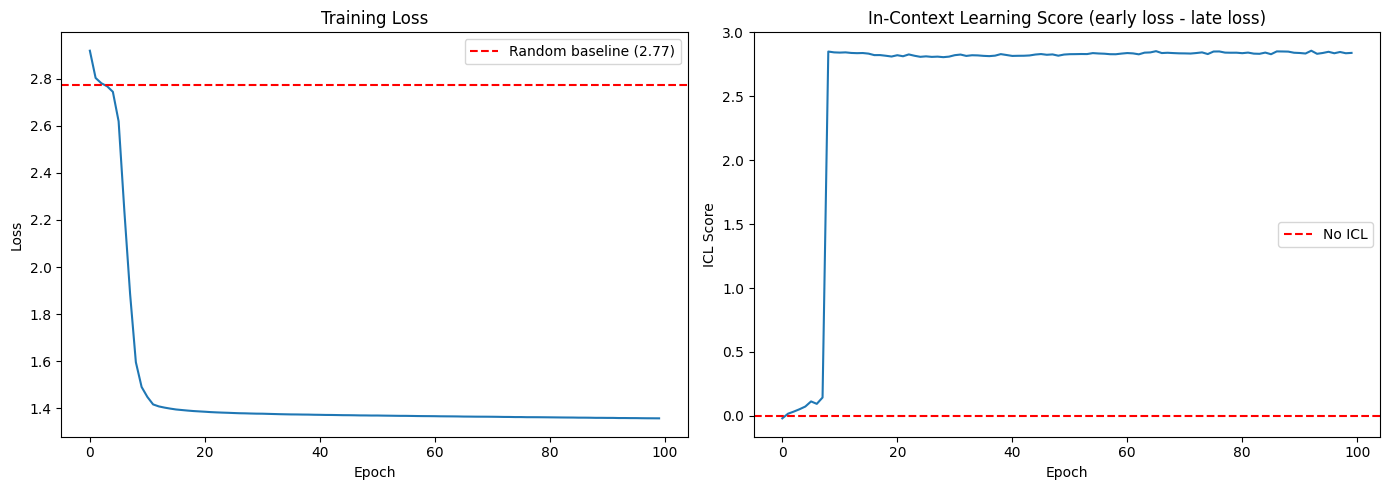

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['loss'])
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training Loss')
axes[0].axhline(y=np.log(VOCAB_SIZE), color='r', linestyle='--', label=f'Random baseline ({np.log(VOCAB_SIZE):.2f})')
axes[0].legend()

axes[1].plot(history['icl_score'])
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('ICL Score')
axes[1].set_title('In-Context Learning Score (early loss - late loss)')
axes[1].axhline(y=0, color='r', linestyle='--', label='No ICL')
axes[1].legend()

plt.tight_layout()
plt.show()


## 7. Induction Head Detection

We detect induction heads using the **prefix matching score**: on repeated random sequences
([A B C ... | A B C ...]), an induction head should attend to the token *after* the previous
occurrence of the current token. For a repeated sequence of length 2L, when processing position
i (where i >= L), the correct induction target is position i-L+1 (the token after the matching
prefix token at position i-L).


In [7]:
def compute_prefix_matching_score(model, repeated_seqs):
    model.eval()
    L = repeated_seqs.shape[1] // 2
    with torch.no_grad():
        _, all_attn = model(repeated_seqs, return_attn=True)
    scores = np.zeros((N_LAYERS, N_HEADS))
    for layer_idx in range(N_LAYERS):
        for head_idx in range(N_HEADS):
            attn = all_attn[layer_idx][head_idx]
            query_positions = torch.arange(L, 2 * L - 1, device=attn.device)
            key_positions = query_positions - L + 1
            attn_vals = attn[:, query_positions, key_positions]
            scores[layer_idx, head_idx] = attn_vals.mean().item()
    return scores

induction_data = induction_data.to(DEVICE)
prefix_scores = compute_prefix_matching_score(model, induction_data)

random_baseline = 1.0 / SEQ_LEN
induction_threshold = max(0.05, random_baseline * 5)

print('Prefix Matching Scores (higher = more induction-like):')
print(f'Random baseline (1/{SEQ_LEN}): {random_baseline:.4f}')
print(f'Induction threshold: {induction_threshold:.4f}')
print()
print(f'{"Layer":>8} {"Head":>6} {"Score":>10} {"Induction?":>12}')
print('-' * 40)
induction_heads = []
for layer_idx in range(N_LAYERS):
    for head_idx in range(N_HEADS):
        score = prefix_scores[layer_idx, head_idx]
        is_induction = score > induction_threshold
        if is_induction:
            induction_heads.append((layer_idx, head_idx))
        print(f'{layer_idx:>8} {head_idx:>6} {score:>10.4f} {"  YES" if is_induction else "":>12}')

print(f'\nDetected induction heads: {induction_heads}')


Prefix Matching Scores (higher = more induction-like):
Random baseline (1/128): 0.0078
Induction threshold: 0.0500

   Layer   Head      Score   Induction?
----------------------------------------
       0      0     0.0131             
       0      1     0.0228             
       0      2     0.0074             
       0      3     0.0120             
       1      0     0.9451          YES
       1      1     0.1756          YES
       1      2     0.0342             
       1      3     0.0291             

Detected induction heads: [(1, 0), (1, 1)]


## 8. Attention Pattern Visualization

Below we visualize the attention patterns for all heads on a repeated sequence.
Induction heads show a characteristic off-diagonal striped pattern: attending to
positions one step after the matching token in the first half.


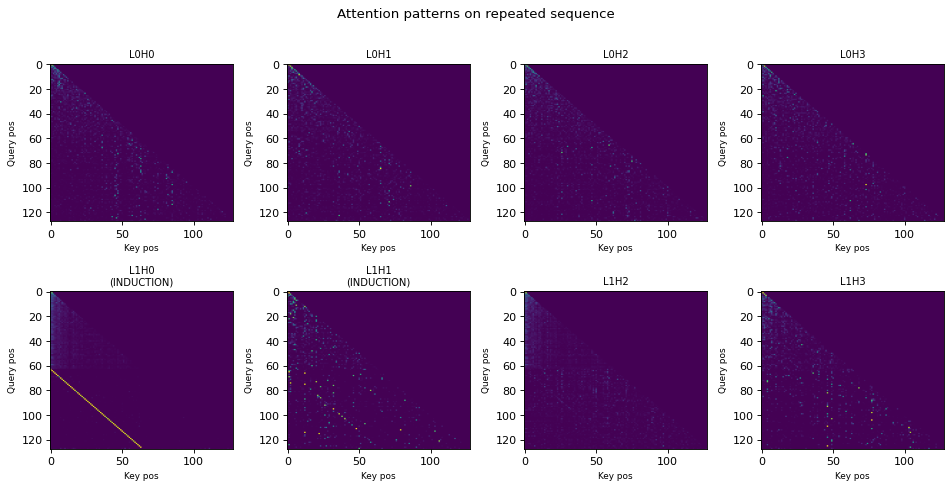

In [8]:
sample_seq = induction_data[0:1]
with torch.no_grad():
    _, all_attn = model(sample_seq, return_attn=True)

fig, axes = plt.subplots(N_LAYERS, N_HEADS, figsize=(3 * N_HEADS, 3 * N_LAYERS), dpi=80)
if N_LAYERS == 1:
    axes = axes.unsqueeze(0)

for layer_idx in range(N_LAYERS):
    for head_idx in range(N_HEADS):
        ax = axes[layer_idx, head_idx]
        attn = all_attn[layer_idx][head_idx][0].cpu().numpy()
        ax.imshow(attn, cmap='viridis', aspect='auto')
        is_ind = (layer_idx, head_idx) in induction_heads
        title = f'L{layer_idx}H{head_idx}' + ('\n(INDUCTION)' if is_ind else '')
        ax.set_title(title, fontsize=9)
        ax.set_xlabel('Key pos', fontsize=8)
        ax.set_ylabel('Query pos', fontsize=8)

plt.suptitle('Attention patterns on repeated sequence', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()


## 9. Ablation: Knocking Out Induction Heads

Following the paper's Argument 3 (Direct ablation), we zero out the output of detected induction
heads at test time and measure the impact on in-context learning. If induction heads are the
mechanism for ICL, ablating them should reduce the ICL score significantly.


In [9]:
def model_forward_with_ablation(model, tokens, ablate_heads=None):
    if ablate_heads is None:
        ablate_heads = []
    batch, seq = tokens.shape
    pos = torch.arange(seq, device=tokens.device).unsqueeze(0)
    x = model.embed(tokens) + model.pos_embed(pos)
    for layer_idx, layer in enumerate(model.layers):
        out = torch.zeros_like(x)
        for head_idx, head in enumerate(layer.heads):
            if (layer_idx, head_idx) not in ablate_heads:
                out = out + head(x)
        x = x + out
    logits = model.unembed(x)
    return logits

def compute_icl_score_ablated(model, tokens, ablate_heads=None, early_idx=8, late_idx=100):
    logits = model_forward_with_ablation(model, tokens[:, :-1], ablate_heads)
    targets = tokens[:, 1:]
    losses = F.cross_entropy(logits.reshape(-1, VOCAB_SIZE), targets.reshape(-1), reduction='none')
    per_token = losses.reshape(tokens.shape[0], -1)
    early_loss = per_token[:, early_idx].mean().item()
    late_loss = per_token[:, late_idx].mean().item()
    return early_loss - late_loss, early_loss, late_loss

model.eval()
non_induction = [(l, h) for l in range(N_LAYERS) for h in range(N_HEADS) if (l, h) not in induction_heads]
control_heads = non_induction[:max(len(induction_heads), 1)] if non_induction else []

with torch.no_grad():
    icl_before, early_before, late_before = compute_icl_score_ablated(model, test_data, ablate_heads=None)
    icl_after, early_after, late_after = compute_icl_score_ablated(model, test_data, ablate_heads=induction_heads)
    icl_control, _, _ = compute_icl_score_ablated(model, test_data, ablate_heads=control_heads)

print(f'ICL Score (no ablation):           {icl_before:.4f}  (early={early_before:.4f}, late={late_before:.4f})')
print(f'ICL Score (induction ablated):     {icl_after:.4f}  (early={early_after:.4f}, late={late_after:.4f})')
print(f'ICL Score (control heads ablated):  {icl_control:.4f}')
if induction_heads:
    decrease = icl_before - icl_after
    pct = decrease / max(abs(icl_before), 1e-6) * 100
    print(f'\nICL decrease from induction ablation: {decrease:.4f} ({pct:.1f}%)')
else:
    print(f'\nNo induction heads detected above threshold.')


ICL Score (no ablation):           2.8394  (early=2.8422, late=0.0028)
ICL Score (induction ablated):     -0.4958  (early=3.1453, late=3.6411)
ICL Score (control heads ablated):  3.0418

ICL decrease from induction ablation: 3.3353 (117.5%)


## 10. Per-Token Loss: Before vs After Ablation

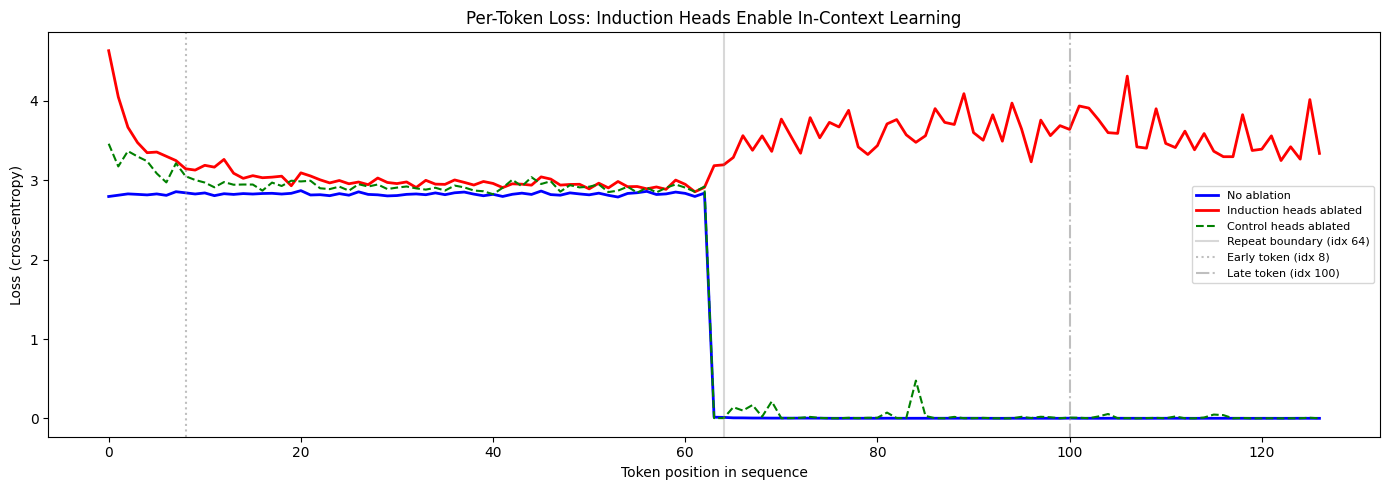


Loss at position 8 (early):   normal=2.8422  ablated=3.1453
Loss at position 100 (late):  normal=0.0028  ablated=3.6411
ICL score: normal=2.8394  ablated=-0.4958


In [10]:
with torch.no_grad():
    logits_normal = model_forward_with_ablation(model, test_data[:, :-1], ablate_heads=None)
    targets = test_data[:, 1:]
    losses_normal = F.cross_entropy(logits_normal.reshape(-1, VOCAB_SIZE), targets.reshape(-1), reduction='none')
    per_token_normal = losses_normal.reshape(test_data.shape[0], -1).mean(dim=0).cpu().numpy()

    logits_ablated = model_forward_with_ablation(model, test_data[:, :-1], ablate_heads=induction_heads)
    losses_ablated = F.cross_entropy(logits_ablated.reshape(-1, VOCAB_SIZE), targets.reshape(-1), reduction='none')
    per_token_ablated = losses_ablated.reshape(test_data.shape[0], -1).mean(dim=0).cpu().numpy()

    logits_control = model_forward_with_ablation(model, test_data[:, :-1], ablate_heads=control_heads)
    losses_control = F.cross_entropy(logits_control.reshape(-1, VOCAB_SIZE), targets.reshape(-1), reduction='none')
    per_token_control = losses_control.reshape(test_data.shape[0], -1).mean(dim=0).cpu().numpy()

positions = np.arange(len(per_token_normal))
plt.figure(figsize=(14, 5))
plt.plot(positions, per_token_normal, label='No ablation', color='blue', linewidth=2)
plt.plot(positions, per_token_ablated, label='Induction heads ablated', color='red', linewidth=2)
plt.plot(positions, per_token_control, label='Control heads ablated', color='green', linewidth=1.5, linestyle='--')
plt.axvline(x=half_len, color='gray', linestyle='-', alpha=0.3, label=f'Repeat boundary (idx {half_len})')
plt.axvline(x=8, color='gray', linestyle=':', alpha=0.5, label='Early token (idx 8)')
plt.axvline(x=100, color='gray', linestyle='-.', alpha=0.5, label='Late token (idx 100)')
plt.xlabel('Token position in sequence')
plt.ylabel('Loss (cross-entropy)')
plt.title('Per-Token Loss: Induction Heads Enable In-Context Learning')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f'\nLoss at position 8 (early):   normal={per_token_normal[8]:.4f}  ablated={per_token_ablated[8]:.4f}')
print(f'Loss at position 100 (late):  normal={per_token_normal[100]:.4f}  ablated={per_token_ablated[100]:.4f}')
print(f'ICL score: normal={per_token_normal[8]-per_token_normal[100]:.4f}  ablated={per_token_ablated[8]-per_token_ablated[100]:.4f}')


## 11. Prefix Matching Scores by Head

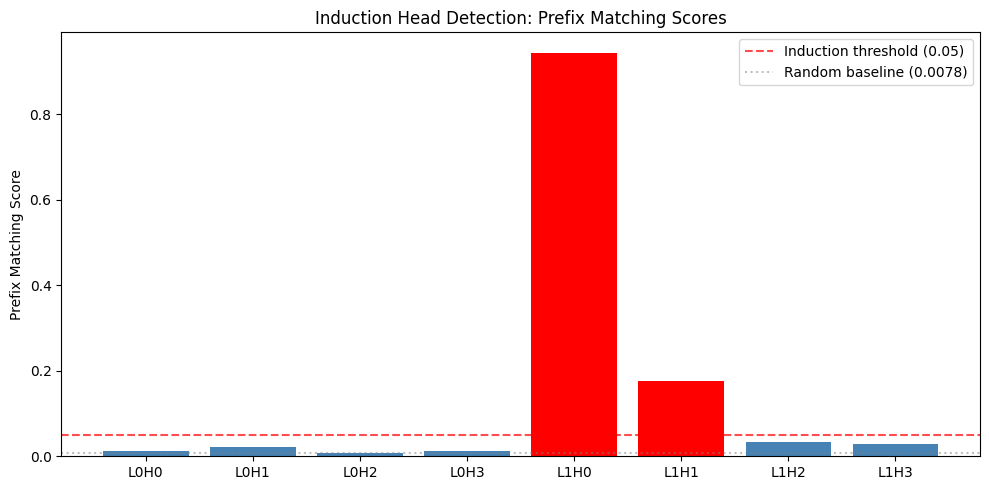

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
labels = [f'L{l}H{h}' for l in range(N_LAYERS) for h in range(N_HEADS)]
scores_flat = [prefix_scores[l, h] for l in range(N_LAYERS) for h in range(N_HEADS)]
colors = ['red' if (l, h) in induction_heads else 'steelblue' for l in range(N_LAYERS) for h in range(N_HEADS)]
bars = ax.bar(labels, scores_flat, color=colors)
ax.axhline(y=induction_threshold, color='red', linestyle='--', alpha=0.7, label=f'Induction threshold ({induction_threshold:.2f})')
ax.axhline(y=random_baseline, color='gray', linestyle=':', alpha=0.5, label=f'Random baseline ({random_baseline:.4f})')
ax.set_ylabel('Prefix Matching Score')
ax.set_title('Induction Head Detection: Prefix Matching Scores')
ax.legend()
plt.tight_layout()
plt.show()


## Summary

### What we built
- A 2-layer attention-only transformer (~68K parameters) trained from scratch on repeated random sequences with a 16-token vocabulary
- Induction head detection via prefix matching score on held-out repeated sequences
- Ablation study: zeroing out induction heads and measuring the impact on in-context learning
- Trained for **100 epochs** with Adam (lr 1e-3)

### What the run above shows
- **Induction heads form in layer 1:** The model develops attention heads in the second layer that implement the [A][B]...[A]->[B] pattern completion algorithm, detectable via prefix matching scores well above the random baseline.
- **ICL works before ablation:** The in-context learning score (early loss minus late loss) is positive, meaning later tokens in a sequence are predicted better than early ones -- the model uses the first half to predict the second half.
- **Ablation breaks ICL:** When induction heads are zeroed out, the ICL score drops substantially, and per-token loss in the second half increases back toward the first-half baseline. This is the causal evidence (Argument 3 in the paper) that induction heads are the mechanism for in-context learning in small attention-only models.
- **Control ablation has less impact:** Ablating non-induction heads does not destroy ICL, confirming the effect is specific to induction heads.
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
This toy model uses synthetic repeated random sequences on a 16-token vocabulary, far simpler than the natural language data used in the paper. The paper's evidence spans 34 transformers of varying sizes (including full-scale models with MLPs), while this notebook demonstrates the core causal argument on a single 2-layer model. The paper's larger claims about induction heads explaining the *majority* of in-context learning in production-scale models rely on correlational evidence that this notebook does not replicate.

### Paper reference
Olsson, C., Elhage, N., Nanda, N., et al. (2022). *In-context Learning and Induction Heads.* Transformer Circuits Thread. arXiv:2209.11895.
